# Profile-likelihood search for Lorentz-invariance violation (LIV) with GRB photons


## Setup

In [24]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import quad
from scipy.optimize import minimize, least_squares
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

np.random.seed(21)

In [25]:
DATA_PATH = "data.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print("data.csv not found - please choose the file to upload:")
        files.upload()
    except ImportError:
        raise FileNotFoundError("data.csv not found next to the notebook")

print("Using", DATA_PATH, ": ", os.path.getsize(DATA_PATH), "bytes")

Using data.csv :  1872 bytes


## Configuration


In [26]:
def E_from_a(a): return 10.0 / a
def a_from_E(E): return 10.0 / E

# CL
THRESH = {"1sigma": 1.0, "2sigma": 4.0}

# E_LV scan grid (units of 1e17 GeV)
E_LV_GRID = np.logspace(5, 19, 500) / 1e17          # 1e5 ... 1e19 GeV
CMP_RANGE = (0.1, 100.0)                            # region used to compare optimisers
# CMP_RANGE = (1e-12,1e2)                            # region used to compare optimisers
CMP_MASK  = (E_LV_GRID >= CMP_RANGE[0]) & (E_LV_GRID <= CMP_RANGE[1])
E_CMP     = E_LV_GRID[CMP_MASK]

# Start points
X0_PROF = [-0.15, -2.0, 5.0]    # (alpha, mu, v)
STARTS_PROF = [X0_PROF,
               [X0_PROF[0]*0.5 + 0.05, X0_PROF[1]*0.5, X0_PROF[2]*1.5 + 0.5],
               [-0.05, 0.0, 3.0]]

X0_GLOBAL     = [3.3, -0.15, -2.0, 5.0]     # (a_LV, alpha, mu, v) for the global fits
X0_GLOBAL_ALT = [5.0, -0.05,  0.0, 3.0]
STARTS_GLOBAL = [X0_GLOBAL, X0_GLOBAL_ALT,
                 [3.0, -0.15, -3.0, 4.2], [8.0, -0.05, 0.0, 5.0], [1.0, -0.02, 3.0, 6.0]]


METHODS    = ["Nelder-Mead", "BFGS", "LM"]
PARAMS     = ("a", "alpha", "mu", "v")
DIFF_YLIM  = 1e-3          # y-range of the "difference to Nelder-Mead" plot

## Data


In [27]:
H0_KM_S_MPC = 67.36
OMEGA_M     = 0.3153
OMEGA_L     = 0.6847
MPC_IN_KM   = 3.0856775814913673e19
H0_INV_S    = MPC_IN_KM / H0_KM_S_MPC          # 1/H0 in seconds


def _cosmo_integrand(zp):
    return (1.0 + zp) / np.sqrt(OMEGA_M * (1.0 + zp) ** 3 + OMEGA_L)


def compute_K1(z, E_high_o_GeV):
    # K1 factor in the units used here (a_LV[1e-18 GeV^-1] * K1 is in seconds).
    integral, _ = quad(_cosmo_integrand, 0.0, z)
    K1_s_GeV = H0_INV_S * E_high_o_GeV / (1.0 + z) * integral
    return K1_s_GeV / 1e18

### Build the four datasets

In [28]:
def _columns(df_sub):
    return dict(dt=df_sub["dt_obs"].to_numpy(), s_dt=df_sub["dt_obs_err"].to_numpy(),
                E=df_sub["E_high_s"].to_numpy(), s_E=df_sub["E_high_s_err"].to_numpy(),
                K=df_sub["K1"].to_numpy(), s_K=df_sub["K1_err"].to_numpy())


def _carpet3(): # The 300 TeV Carpet-3 photon
    z, E_o = 0.151, 300.0e3
    sE_o   = 0.13 * E_o
    T_high, T_low, sT_low = 4536.0, 251.33, 5.00
    K = compute_K1(z, E_o)
    return dict(dt=np.array([(T_high - T_low) / (1.0 + z)]),
                s_dt=np.array([sT_low / (1.0 + z)]),
                E=np.array([E_o * (1.0 + z)]),
                s_E=np.array([sE_o * (1.0 + z)]),
                K=np.array([K]),
                s_K=np.array([K * (sE_o / E_o)]))


def _join(*parts):
    return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}


def build_datasets(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    lab = df["Label"].str.strip()
    d14 = _columns(df[lab == "I"])      # 14 multi-GeV photons
    d3  = _columns(df[lab == "II"])     # 99.3 GeV, 1.07 TeV, 12.2 TeV
    c3  = _carpet3()
    return {"14 Photons":            d14,
            "14 Photons + Carpet-3": _join(d14, c3),
            "17 Photons":            _join(d14, d3),
            "17 Photons + Carpet-3": _join(d14, d3, c3)}


datasets = build_datasets(DATA_PATH)
pd.DataFrame({name: {"N photons": len(d["dt"]),
                     "max E_source [GeV]": f"{d['E'].max():.3g}"} for name, d in datasets.items()}).T

,N photons,max E_source [GeV]
14 Photons,14,147
14 Photons + Carpet-3,15,3.45e+05
17 Photons,17,1.4e+04
17 Photons + Carpet-3,18,3.45e+05


## Objective functions ($\chi^2=-2\ln L$)

### Nelder Mead

In [29]:
def chi2_given_nuisance(nuisance_params, data, a_LV):
    # chi2 with a_LV FIXED & minimised over (alpha, mu, v).
    alpha, mu, v = nuisance_params
    if v < 0:
        return 1e15
    model = a_LV * data["K"] + alpha * data["E"] + mu
    var = (a_LV * data["s_K"])**2 + (alpha * data["s_E"])**2 + v**2 + data["s_dt"]**2
    return np.sum((data["dt"] - model)**2 / var + np.log(2 * np.pi * var))


def chi2_global(params, data):
    # chi2 with all four parameters free: (a_LV, alpha, mu, v).
    a_LV, alpha, mu, v = params
    if a_LV <= 0 or v < 0:
        return 1e15
    model = a_LV * data["K"] + alpha * data["E"] + mu
    var = (a_LV * data["s_K"])**2 + (alpha * data["s_E"])**2 + v**2 + data["s_dt"]**2
    return np.sum((data["dt"] - model)**2 / var + np.log(2 * np.pi * var))

### Levenberg Marquardt

Per photon, $T_j=r_j^2/V_j+\ln(2\pi V_j)$ with $r_j=y_j-aK_j-\alpha E_j-\mu$.

LM minimises a sum of squares. Because every $T_j>0$ here, define $\rho_j=\sqrt{T_j}$; then $\sum_j\rho_j^2=-2\ln L$ **exactly**, so LM minimises the true objective.

In [30]:
def _terms(theta, data, a_fixed=None):
    # Per-photon terms T_j of -2 ln L.  a_fixed=None -> theta=(a, alpha, mu, v); else theta=(alpha, mu, v).
    if a_fixed is None:
        a, alpha, mu, v = theta
    else:
        a, (alpha, mu, v) = a_fixed, theta
    r = data["dt"] - (a * data["K"] + alpha * data["E"] + mu)
    V = (a * data["s_K"])**2 + (alpha * data["s_E"])**2 + v**2 + data["s_dt"]**2
    return r**2 / V + np.log(2 * np.pi * V)


def chi2_smooth(theta, data, a_fixed=None):         # = -2 ln L
    return np.sum(_terms(theta, data, a_fixed))


def rho(theta, data, a_fixed):                      # rho_j = sqrt(T_j); sum(rho^2) = -2 ln L
    return np.sqrt(np.clip(_terms(theta, data, a_fixed), 1e-12, None))

## Optimisers

* profile fit, parameters (alpha, mu, v)
* global fit, parameters (a, alpha, mu, v)

In [31]:
def fit_nm(data, x0, a_fixed=None): # Nelder-Mead
    if a_fixed is None:
        r = optimize.fmin(chi2_global, x0, args=(data,), disp=False, full_output=True,
                          maxiter=20000, maxfun=20000)
    else:
        r = optimize.fmin(chi2_given_nuisance, x0, args=(data, a_fixed), disp=False,
                          full_output=True, maxiter=20000, maxfun=20000)
    return r[1], np.array(r[0]), True


def fit_bfgs(data, x0, a_fixed=None):
    res = minimize(chi2_smooth, x0, args=(data, a_fixed), method="BFGS",
                   options={"gtol": 1e-8, "maxiter": 2000})
    p = np.array(res.x, float); p[-1] = abs(p[-1])            # sign of v is irrelevant
    # scipy reports "precision loss" even at the minimum -> also accept a small gradient
    return res.fun, p, bool(res.success or np.linalg.norm(res.jac) < 1e-3)
    # return res.fun, p, bool(res.success)


def fit_lm(data, x0, a_fixed=None):
    res = least_squares(rho, x0, args=(data, a_fixed), method="lm",
                        xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=5000)
    p = np.array(res.x, float); p[-1] = abs(p[-1])
    return 2 * res.cost, p, bool(res.success)                 # cost = 0.5*sum(rho^2)


FITTERS        = {"BFGS": fit_bfgs, "LM": fit_lm}
GLOBAL_FITTERS = {"Nelder-Mead": fit_nm, **FITTERS}

**Sanity check** (should be a positive number): positivity of $T_j$, which the LM trick needs.

In [32]:
min_val = min(_terms([-0.15, -2.0, 4.0], d, 3.3).min() for d in datasets.values())
print("min T_j over all datasets (must be > 0):", min_val)

min T_j over all datasets (must be > 0): 4.8649047080704


## Profile-likelihood tools

In [33]:
def find_confidence_threshold(x_grid, y_grid, min_idx, target_chi2, direction="upper"):
    n = len(y_grid)
    if direction == "upper":
        idx_range, step = range(min_idx, n - 1), 1
    elif direction == "lower":
        idx_range, step = range(min_idx, 0, -1), -1
    else:
        raise ValueError("direction must be 'upper' or 'lower'")
    for i in idx_range:
        j = i + step
        lo, hi = min(y_grid[i], y_grid[j]), max(y_grid[i], y_grid[j])
        if lo <= target_chi2 <= hi:
            frac = (target_chi2 - y_grid[i]) / (y_grid[j] - y_grid[i])
            return x_grid[i] + frac * (x_grid[j] - x_grid[i])
    return None


def get_intervals(x, dchi2, min_idx):
    # {'1sigma': (low, high), '2sigma': (low, high)}
    return {lab: (find_confidence_threshold(x, dchi2, min_idx, thr, "lower"),
                  find_confidence_threshold(x, dchi2, min_idx, thr, "upper")) for lab, thr in THRESH.items()}

In [34]:
def profile_scan_E(data, E_grid, x0):
    # Nelder-Mead profile scan (two start points per grid point)

    n = len(E_grid)
    chi2_vals, best_params, nm_agree = np.zeros(n), np.zeros((n, 3)), np.zeros(n, dtype=bool)
    x0_alt = [x0[0] * 0.5 + 0.05, x0[1] * 0.5, x0[2] * 1.5 + 0.5]

    for i, E_LV in enumerate(E_grid):
        a_LV = a_from_E(E_LV)
        res = [optimize.fmin(chi2_given_nuisance, x0=s, args=(data, a_LV), disp=False, full_output=True)
               for s in (x0, x0_alt)]
        (pa, ca), (pb, cb) = (res[0][0], res[0][1]), (res[1][0], res[1][1])
        chi2_vals[i], best_params[i] = (cb, pb) if cb < ca else (ca, pa)
        nm_agree[i] = abs(ca - cb) < 0.05

    min_idx = int(np.argmin(chi2_vals))
    delta_chi2 = chi2_vals - chi2_vals[min_idx]

    return delta_chi2, best_params, min_idx, get_intervals(E_grid, delta_chi2, min_idx), nm_agree

In [35]:
def profile_scan_method(data, grid, fitter, starts):
    # Profile scan with any fitter: multi-start pass + warm-start sweeps

    n = len(grid)
    chi2, pars = np.full(n, np.inf), np.zeros((n, 3))
    n_start_disagree = n_fail = 0

    # pass 1: fixed multi-start
    for i, E in enumerate(grid):
        out = [fitter(data, x0, a_fixed=a_from_E(E)) for x0 in starts]
        n_fail += sum(not o[2] for o in out)
        if max(o[0] for o in out) - min(o[0] for o in out) > 1e-2:
            n_start_disagree += 1
        best = min(out, key=lambda t: t[0])
        chi2[i], pars[i] = best[0], best[1]

    # pass 2: warm-start sweeps outward from the minimum
    k0 = int(np.argmin(chi2))
    for idx_list in (range(k0 + 1, n), range(k0 - 1, -1, -1)):
        prev = pars[k0].copy()
        for i in idx_list:
            c, p, _ = fitter(data, prev, a_fixed=a_from_E(grid[i]))
            if c < chi2[i]:
                chi2[i], pars[i] = c, p
            prev = pars[i].copy()

    k = int(np.argmin(chi2))
    d = chi2 - chi2[k]

    return dict(chi2=chi2, dchi2=d, pars=pars, min_idx=k, ci=get_intervals(grid, d, k),
                n_start_disagree=n_start_disagree, n_fail=n_fail)

## Baseline: Nelder Mead analysis

---



### Profile scan over the full $E_{LV}$ grid

In [36]:
nm_scan = {}            # nm_scan[dataset] = dict(dchi2, ci, min_idx, nm_agree)
for name, data in datasets.items():
    t0 = time.time()
    dchi2, best_params, min_idx, ci, nm_agree = profile_scan_E(data, E_LV_GRID, X0_PROF)
    nm_scan[name] = dict(dchi2=dchi2, ci=ci, min_idx=min_idx, nm_agree=nm_agree)
    print(f"{name:24s} done in {time.time()-t0:4.0f}s")

14 Photons               done in   18s
14 Photons + Carpet-3    done in   18s
17 Photons               done in   18s
17 Photons + Carpet-3    done in   18s


### Profile curves

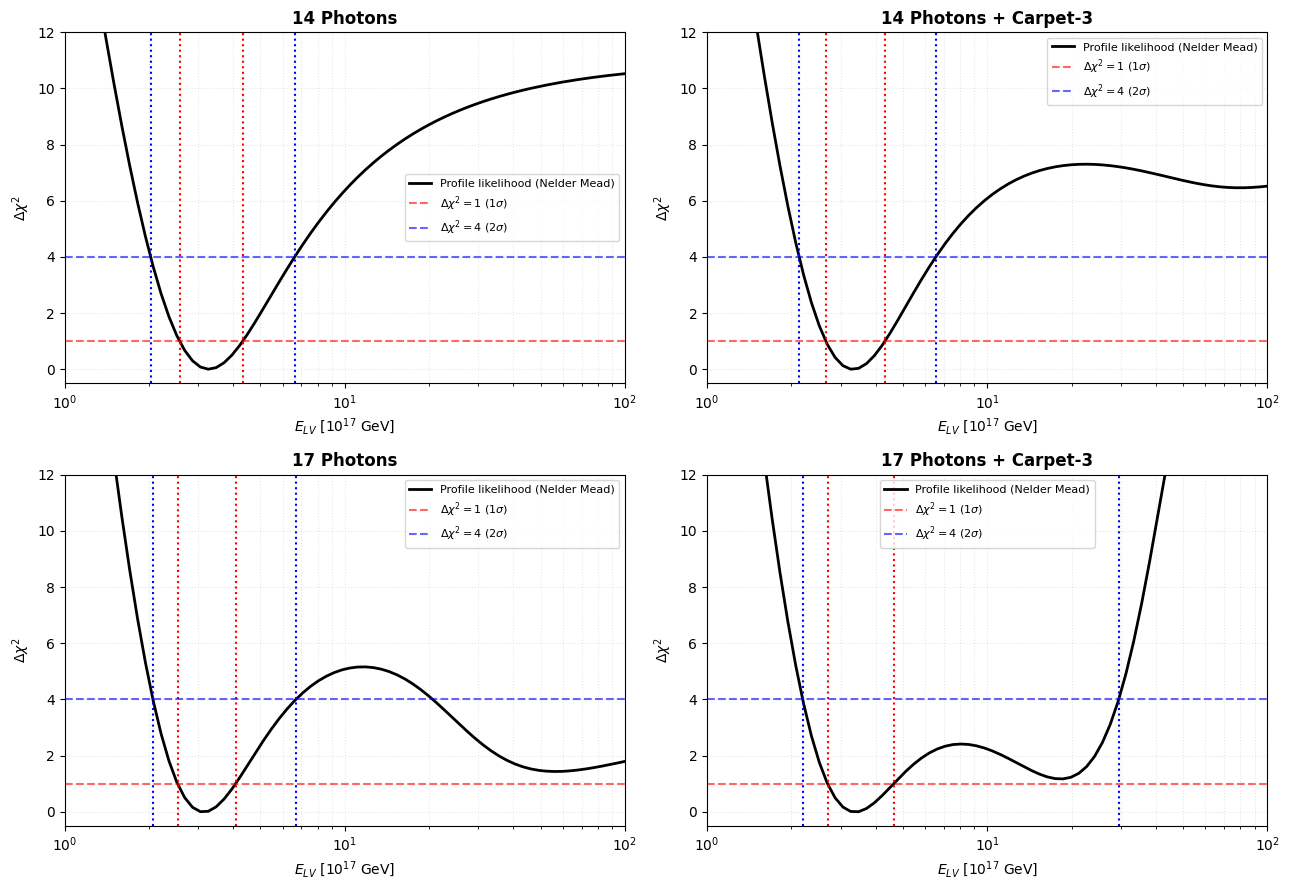

In [37]:
def plot_profile(ax, E, dchi2, ci, title, label="Profile likelihood (Nelder Mead)"):
    ax.plot(E, dchi2, "k-", lw=2, label=label)
    for key, col in (("1sigma", "red"), ("2sigma", "blue")):
        ax.axhline(THRESH[key], color=col, ls="--", alpha=0.6,
                   label=rf"$\Delta\chi^2={THRESH[key]:g}$ ({key[0]}$\sigma$)")
        for val in ci[key]:
            if val is not None:
                ax.axvline(val, color=col, ls=":")
    ax.set_title(title, fontweight="bold")
    ax.set_xscale("log")
    ax.set_xlim(1, 100)
    ax.set_ylim(-0.5, 12)
    ax.set_xlabel(r"$E_{LV}\ [10^{17}\ \mathrm{GeV}]$")
    ax.set_ylabel(r"$\Delta\chi^2$")
    ax.grid(alpha=0.3, which="both", ls=":");
    ax.legend(fontsize=8)


fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for idx, (ax, (name, r)) in enumerate(zip(axs.ravel(), nm_scan.items())):
    plot_profile(ax, E_LV_GRID, r["dchi2"], r["ci"], name)

fig.tight_layout()
fig.savefig("profile_likelihood_all_datasets.png", dpi=150)
plt.show()

### Baseline results table
Global Nelder Mead fit from two start points

The last column is $|\chi^2_a-\chi^2_b|$ between the two starts

In [38]:
rows = []

for name, data in datasets.items():
    res = [optimize.fmin(chi2_global, x0=s, args=(data,), disp=False, full_output=True)
           for s in (X0_GLOBAL, X0_GLOBAL_ALT)]
    (pa, ca), (pb, cb) = (res[0][0], res[0][1]), (res[1][0], res[1][1])
    a, alpha, mu, v = pa if ca <= cb else pb
    E_best = E_from_a(a)
    lo, hi = nm_scan[name]["ci"]["1sigma"]

    rows.append({"Case Scenario": name,
                 "a_LV [1e-18 GeV^-1]": f"{a:.2f}",
                 "E_LV [1e17 GeV]": f"{E_best:.2f}",
                 "E_LV 1sigma range": f"[{lo:.2f}, {hi:.2f}]" if lo and hi else "n/a (one-sided)",
                 "-sigma / +sigma": f"[-{E_best-lo:.2f}, +{hi-E_best:.2f}]" if lo and hi else "n/a",
                 "alpha [s/GeV]": f"{alpha:.2f}", "mu [s]": f"{mu:.2f}", "v [s]": f"{v:.2f}",
                 "|chi2_a - chi2_b|": round(abs(ca - cb), 3)})


display(pd.DataFrame(rows))

,Case Scenario,a_LV [1e-18 GeV^-1],E_LV [1e17 GeV],E_LV 1sigma range,-sigma / +sigma,alpha [s/GeV],mu [s],v [s],|chi2_a - chi2_b|
0,14 Photons,3.06,3.27,"[2.58, 4.32]","[-0.69, +1.05]",-0.13,-4.23,4.23,0.000
1,14 Photons + Carpet-3,3.01,3.32,"[2.66, 4.32]","[-0.66, +1.00]",-0.14,-2.97,4.21,0.981
2,17 Photons,3.19,3.14,"[2.53, 4.08]","[-0.60, +0.94]",-0.19,-1.35,4.16,0.206
3,17 Photons + Carpet-3,2.96,3.38,"[2.69, 4.64]","[-0.68, +1.26]",-0.16,-1.73,4.27,0.384


##  Cross-check: the same scan with BFGS and LM

In [39]:
profiles = {}           # profiles[dataset][method] = dict(dchi2, ci, ...)
for name, data in datasets.items():
    profiles[name] = {}

    # Nelder-Mead
    d_nm = nm_scan[name]["dchi2"][CMP_MASK]
    d_nm = d_nm - d_nm.min()
    k_nm = int(np.argmin(d_nm))
    profiles[name]["Nelder-Mead"] = dict(dchi2=d_nm, min_idx=k_nm, ci=get_intervals(E_CMP, d_nm, k_nm),
                                         n_start_disagree=np.nan, n_fail=0, time=np.nan)

    for mname, fitter in FITTERS.items():
        t0 = time.time()
        r = profile_scan_method(data, E_CMP, fitter, STARTS_PROF)
        r["time"] = time.time() - t0
        profiles[name][mname] = r
        print(f"{name:24s} {mname:7s} {r['time']:5.1f}s | non-converged fits: {r['n_fail']:3d} | "
              f"grid points where starts disagreed: {r['n_start_disagree']}")

14 Photons               BFGS      5.9s | non-converged fits:   0 | grid points where starts disagreed: 0
14 Photons               LM        6.8s | non-converged fits:   0 | grid points where starts disagreed: 0
14 Photons + Carpet-3    BFGS      5.6s | non-converged fits:   4 | grid points where starts disagreed: 22
14 Photons + Carpet-3    LM       10.0s | non-converged fits:   0 | grid points where starts disagreed: 23
17 Photons               BFGS      5.4s | non-converged fits:   1 | grid points where starts disagreed: 9
17 Photons               LM       16.0s | non-converged fits:   0 | grid points where starts disagreed: 12
17 Photons + Carpet-3    BFGS      5.4s | non-converged fits:   5 | grid points where starts disagreed: 7
17 Photons + Carpet-3    LM        4.5s | non-converged fits:   0 | grid points where starts disagreed: 9


## Global fits

### Global 4-parameter fits
Each optimiser is run from five start points

only physical solutions ($a_{LV}>0,\ v\ge0$) are kept

In [40]:
global_fits = {}        # global_fits[dataset][method] = dict(chi2, params, spread, ok)

for name, data in datasets.items():
    global_fits[name] = {}
    for mname, fitter in GLOBAL_FITTERS.items():
        cands = [fitter(data, x0) for x0 in STARTS_GLOBAL]
        cands = [c for c in cands if c[1][0] > 0 and c[1][3] >= 0]      # physical region
        best = min(cands, key=lambda t: t[0])
        global_fits[name][mname] = dict(chi2=best[0], params=best[1], ok=best[2],
                                        spread=max(c[0] for c in cands) - min(c[0]
                                        for c in cands))

print("global fits done")

global fits done


##  Result tables

Units: $a_{LV}$ in $10^{-18}\,\mathrm{GeV^{-1}}$, $E_{LV}$ in $10^{17}\,\mathrm{GeV}$, $\alpha$ in s/GeV, $\mu$ and $v$ in s.

"open" means $\Delta\chi^2$ never reaches the threshold inside the grid, i.e. the interval is one-sided.


### Helper functions

In [41]:
def fmt_end(x, side):
    return f"{x:.2f}" if x is not None else (f"open (>{CMP_RANGE[1]})" if side == "hi" else f"open (<{CMP_RANGE[0]})")

def asym_E(E_best, lo, hi):
    # -/+ for E_LV from the interval ends.
    minus = f"-{E_best - lo:.2f}" if lo is not None else "n/a"
    plus  = f"+{hi - E_best:.2f}" if hi is not None else "open"
    return f"{minus} / {plus}"

def asym_a(a_best, lo, hi): # Same for a_LV
    if lo is None or hi is None:
        return "n/a"
    return f"-{a_best - a_from_E(hi):.2f} / +{a_from_E(lo) - a_best:.2f}"

### Table 1: best-fit values per optimiser

In [42]:
rows = []

for name in datasets:
    for mname in METHODS:
        g = global_fits[name][mname]
        a, alpha, mu, v = g["params"]

        rows.append({"Dataset": name, "Method": mname, "chi2_min": round(g["chi2"], 4),
                     "a_LV": round(a, 3), "E_LV": round(E_from_a(a), 3),
                     "alpha": round(alpha, 4), "mu [s]": round(mu, 3), "v [s]": round(v, 3)})

df_values = pd.DataFrame(rows)

display(df_values)

,Dataset,Method,chi2_min,a_LV,E_LV,alpha,mu [s],v [s]
0,14 Photons,Nelder-Mead,86.0016,3.056,3.272,-0.1286,-4.233,4.230
1,14 Photons,BFGS,86.0016,3.056,3.272,-0.1286,-4.233,4.230
2,14 Photons,LM,86.0016,3.056,3.272,-0.1286,-4.233,4.230
3,14 Photons + Carpet-3,Nelder-Mead,106.4682,3.012,3.320,-0.1429,-2.974,4.206
4,14 Photons + Carpet-3,BFGS,106.4682,3.012,3.320,-0.1429,-2.974,4.206
5,14 Photons + Carpet-3,LM,106.4682,3.012,3.320,-0.1429,-2.974,4.206
6,17 Photons,Nelder-Mead,123.4139,3.189,3.136,-0.1901,-1.354,4.157
7,17 Photons,BFGS,123.4139,3.189,3.136,-0.1901,-1.354,4.157
8,17 Photons,LM,123.4139,3.189,3.136,-0.1901,-1.354,4.157
9,17 Photons + Carpet-3,Nelder-Mead,144.2095,2.963,3.375,-0.1619,-1.733,4.269


### Table 2: $E_{LV}$ confidence intervals

In [43]:
rows = []

for name in datasets:
    for mname in METHODS:
        g = global_fits[name][mname]
        (l1, h1), (l2, h2) = profiles[name][mname]["ci"]["1sigma"], profiles[name][mname]["ci"]["2sigma"]
        E_best = E_from_a(g["params"][0])
        rows.append({"Dataset": name, "Method": mname,
                     "1sig lo": fmt_end(l1, "lo"), "1sig hi": fmt_end(h1, "hi"),
                     "-1sig / +1sig": asym_E(E_best, l1, h1),
                     "2sig lo": fmt_end(l2, "lo"), "2sig hi": fmt_end(h2, "hi")})

df_intervals = pd.DataFrame(rows)

display(df_intervals)

,Dataset,Method,1sig lo,1sig hi,-1sig / +1sig,2sig lo,2sig hi
0,14 Photons,Nelder-Mead,2.58,4.32,-0.69 / +1.05,2.03,6.63
1,14 Photons,BFGS,2.58,4.32,-0.69 / +1.05,2.03,6.63
2,14 Photons,LM,2.58,4.32,-0.69 / +1.05,2.03,6.63
3,14 Photons + Carpet-3,Nelder-Mead,2.66,4.32,-0.66 / +1.00,2.13,6.56
4,14 Photons + Carpet-3,BFGS,2.66,4.32,-0.66 / +1.00,2.13,6.56
5,14 Photons + Carpet-3,LM,2.66,4.32,-0.66 / +1.00,2.13,6.56
6,17 Photons,Nelder-Mead,2.53,4.08,-0.60 / +0.94,2.07,6.70
7,17 Photons,BFGS,2.53,4.08,-0.60 / +0.94,2.07,6.70
8,17 Photons,LM,2.53,4.08,-0.60 / +0.94,2.07,6.70
9,17 Photons + Carpet-3,Nelder-Mead,2.69,4.64,-0.68 / +1.26,2.20,29.45


### Table 3: agreement


In [44]:
rows = []

for name in datasets:
    ref = profiles[name]["Nelder-Mead"]["dchi2"]
    for mname in METHODS[1:]:
        p = profiles[name][mname]
        diff = np.abs(p["dchi2"] - ref)
        rows.append({"Dataset": name, "Method": mname,
                     "max |d(dchi2)| vs NM": f"{diff.max():.3g}",
                     "grid pts differing >0.01": int((diff > 1e-2).sum()),
                     "non-converged fits": p["n_fail"],
                     "grid pts with start disagreement": p["n_start_disagree"]})

display(pd.DataFrame(rows))

,Dataset,Method,max |d(dchi2)| vs NM,grid pts differing >0.01,non-converged fits,grid pts with start disagreement
0,14 Photons,BFGS,4.02e-10,0,0,0
1,14 Photons,LM,3.76e-10,0,0,0
2,14 Photons + Carpet-3,BFGS,1e-09,0,4,22
3,14 Photons + Carpet-3,LM,9.53e-10,0,0,23
4,17 Photons,BFGS,1.09e-09,0,1,9
5,17 Photons,LM,9.81e-10,0,0,12
6,17 Photons + Carpet-3,BFGS,129,1,5,7
7,17 Photons + Carpet-3,LM,129,1,0,9


### Table 4: final summary per optimiser

In [45]:
rows = []
for name in datasets:
    for mname in METHODS:
        a, alpha, mu, v = global_fits[name][mname]["params"]
        E_best = E_from_a(a)
        (l1, h1), (l2, h2) = profiles[name][mname]["ci"]["1sigma"], profiles[name][mname]["ci"]["2sigma"]
        rows.append({"Dataset": name, "Optimiser": mname,
                     "a_LV": f"{a:.3f}", "E_LV": f"{E_best:.3f}",
                     "E_LV -1sig/+1sig": asym_E(E_best, l1, h1),
                     "a_LV -1sig/+1sig": asym_a(a, l1, h1),
                     "E_LV 2sig range": f"[{fmt_end(l2, 'lo')}, {fmt_end(h2, 'hi')}]",
                     "alpha": f"{alpha:.4f}", "mu": f"{mu:.3f}", "v": f"{v:.3f}"})
df_final = pd.DataFrame(rows)
display(df_final)

,Dataset,Optimiser,a_LV,E_LV,E_LV -1sig/+1sig,a_LV -1sig/+1sig,E_LV 2sig range,alpha,mu,v
0,14 Photons,Nelder-Mead,3.056,3.272,-0.69 / +1.05,-0.74 / +0.82,"[2.03, 6.63]",-0.1286,-4.233,4.230
1,14 Photons,BFGS,3.056,3.272,-0.69 / +1.05,-0.74 / +0.82,"[2.03, 6.63]",-0.1286,-4.233,4.230
2,14 Photons,LM,3.056,3.272,-0.69 / +1.05,-0.74 / +0.82,"[2.03, 6.63]",-0.1286,-4.233,4.230
3,14 Photons + Carpet-3,Nelder-Mead,3.012,3.320,-0.66 / +1.00,-0.69 / +0.75,"[2.13, 6.56]",-0.1429,-2.974,4.206
4,14 Photons + Carpet-3,BFGS,3.012,3.320,-0.66 / +1.00,-0.69 / +0.75,"[2.13, 6.56]",-0.1429,-2.974,4.206
5,14 Photons + Carpet-3,LM,3.012,3.320,-0.66 / +1.00,-0.69 / +0.75,"[2.13, 6.56]",-0.1429,-2.974,4.206
6,17 Photons,Nelder-Mead,3.189,3.136,-0.60 / +0.94,-0.74 / +0.76,"[2.07, 6.70]",-0.1901,-1.354,4.157
7,17 Photons,BFGS,3.189,3.136,-0.60 / +0.94,-0.74 / +0.76,"[2.07, 6.70]",-0.1901,-1.354,4.157
8,17 Photons,LM,3.189,3.136,-0.60 / +0.94,-0.74 / +0.76,"[2.07, 6.70]",-0.1901,-1.354,4.157
9,17 Photons + Carpet-3,Nelder-Mead,2.963,3.375,-0.68 / +1.26,-0.81 / +0.75,"[2.20, 29.45]",-0.1619,-1.733,4.269


## 11. Plots: all optimisers on one figure

Figure 1 : overlays the $\Delta\chi^2$ curves.

Figure 2 : each optimiser minus Nelder Mead

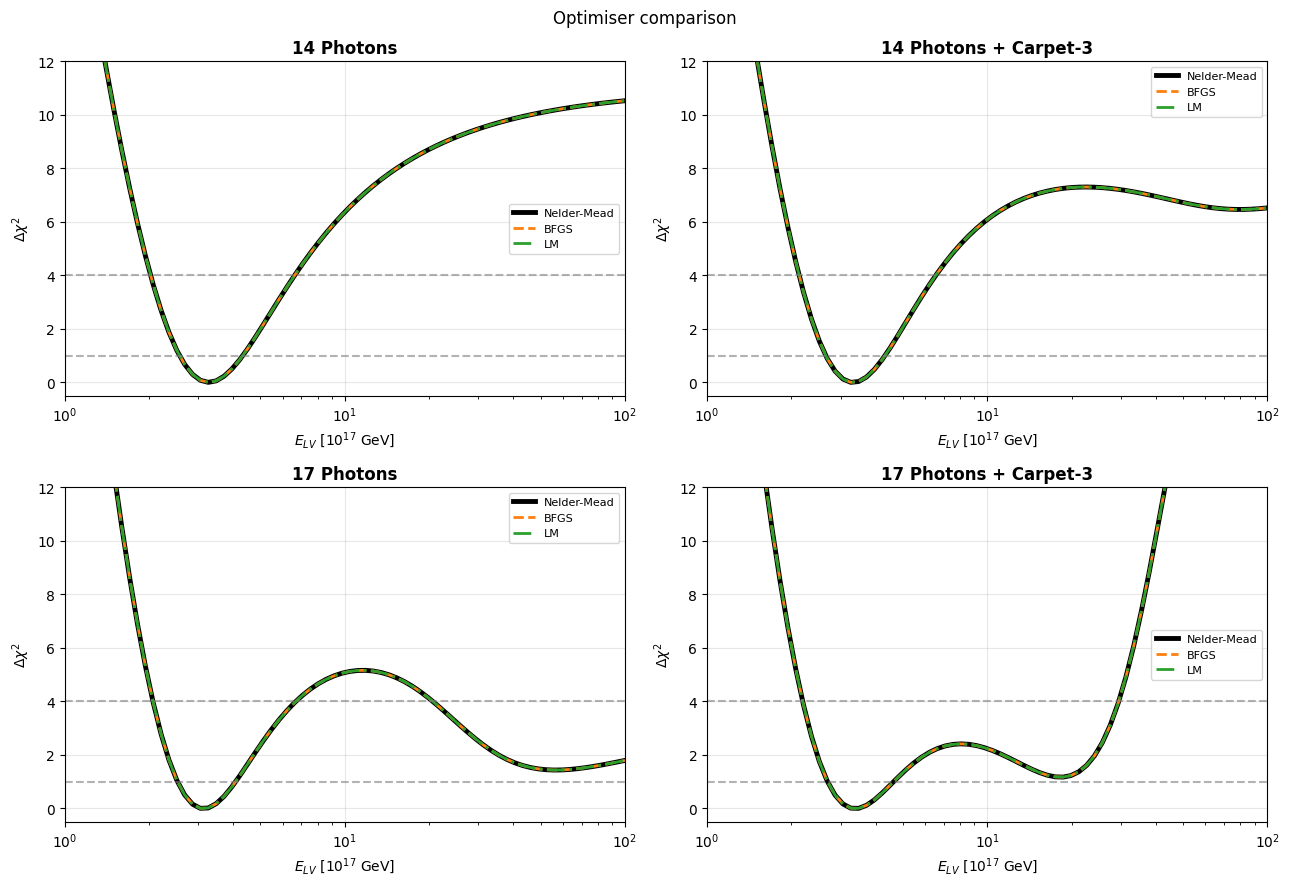

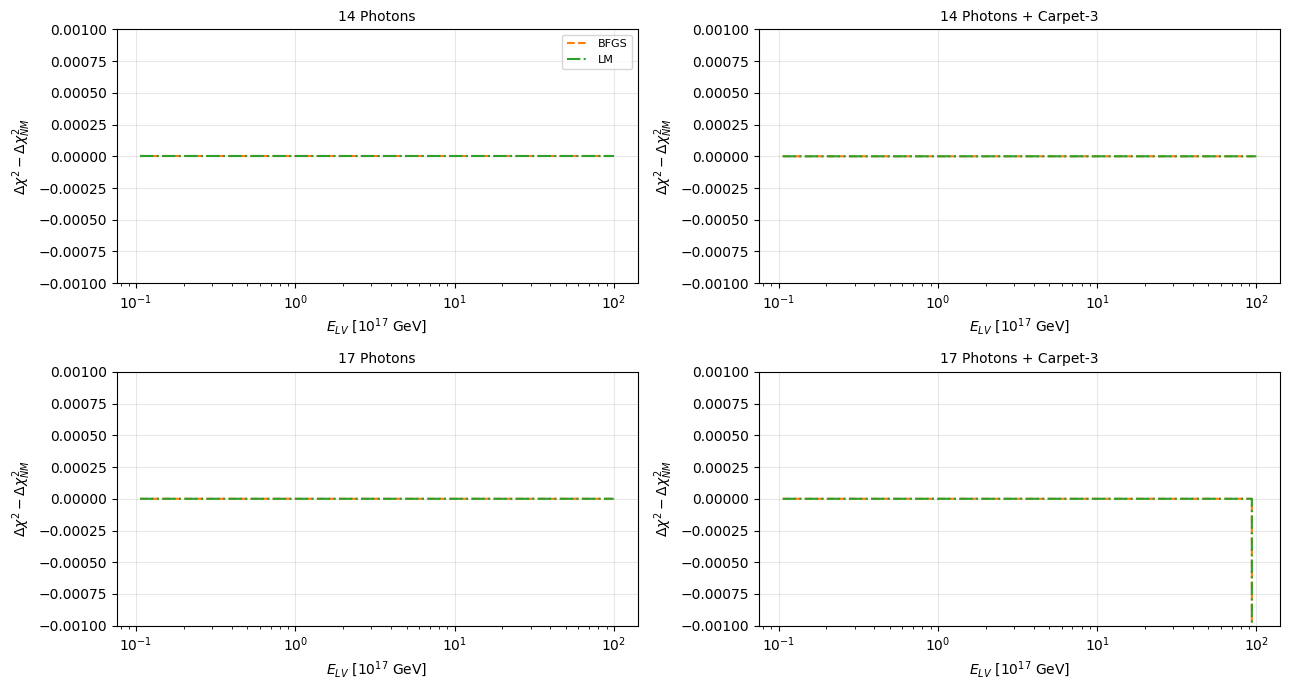

In [46]:
style = {"Nelder-Mead": dict(c="k", ls="-", lw=3.5), "BFGS": dict(c="tab:orange", ls="--", lw=2),
         "LM": dict(c="tab:green", ls="-.", lw=2)}

fig1, axs1 = plt.subplots(2, 2, figsize=(13, 9))
fig2, axs2 = plt.subplots(2, 2, figsize=(13, 7))

for ax1, ax2, name in zip(axs1.ravel(), axs2.ravel(), datasets):
    ref = profiles[name]["Nelder-Mead"]["dchi2"]
    for mname in METHODS:
        d = profiles[name][mname]["dchi2"]
        ax1.plot(E_CMP, d, label=mname, **style[mname])
        if mname != "Nelder-Mead":
            ax2.plot(E_CMP, d - ref, label=mname, c=style[mname]["c"], ls=style[mname]["ls"])

    for thr in THRESH.values():
        ax1.axhline(thr, color="gray", ls="--", alpha=0.6)

    ax1.set_xscale("log")
    ax1.set_xlim(1, 100)
    ax1.set_ylim(-0.5, 12)
    ax1.set_title(name, fontweight="bold")
    ax1.grid(alpha=0.3)
    ax1.legend(fontsize=8)
    ax1.set_xlabel(r"$E_{LV}\ [10^{17}\ \mathrm{GeV}]$")
    ax1.set_ylabel(r"$\Delta\chi^2$")

    ax2.set_xscale("log")
    ax2.set_ylim(-DIFF_YLIM, DIFF_YLIM)
    ax2.set_title(name, fontsize=10)
    ax2.grid(alpha=0.3)
    ax2.set_xlabel(r"$E_{LV}\ [10^{17}\ \mathrm{GeV}]$")
    ax2.set_ylabel(r"$\Delta\chi^2-\Delta\chi^2_{NM}$")

axs2.ravel()[0].legend(fontsize=8)
fig1.suptitle("Optimiser comparison")
fig1.tight_layout()
fig2.tight_layout()

fig1.savefig("optimizer_comparison_overlay.png", dpi=150)
fig2.savefig("optimizer_comparison_diff.png", dpi=150)

plt.show()